# Predicting Customer Term-Deposit Subscription Using Machine Learning

**Applied Machine Learning Capstone Project**  
**Team members:** Chhavi Agarwal (B-9) and Pavitra Singh (B-9)  
**Project type:** Classification  
**Dataset:** Bank Marketing – UCI Machine Learning Repository

---
## Abstract

This project develops and compares machine learning classification models to predict whether a customer will subscribe to a bank term deposit following a marketing campaign. The study uses the Bank Marketing dataset from the UCI Machine Learning Repository. The workflow includes data understanding, exploratory data analysis, preprocessing, model training, validation and final testing. Logistic Regression, Decision Tree and Random Forest are implemented. Since the target classes are imbalanced, the evaluation considers precision, recall, F1-score and ROC-AUC along with accuracy. Random Forest was selected using validation performance and achieved an F1-score of 44.88% and ROC-AUC of 79.90% on the final untouched test dataset.


## 1. Introduction

Banks use marketing campaigns to inform customers about financial products such as term deposits. Contacting every customer in the same way may not be the most efficient approach, because customers do not all respond in the same way.

In this project, the target is to predict whether a customer subscribed to a term deposit. The prediction is a binary classification task: **yes** means the customer subscribed and **no** means the customer did not subscribe.

### 1.1 Problem statement

To build a classification model using customer and campaign information that estimates whether a customer is likely to subscribe to a term deposit.

### 1.2 Objectives

1. Understand the Bank Marketing dataset and its variables.
2. Explore patterns in the customer and campaign data.
3. Prepare the data for machine learning.
4. Train three classification algorithms.
5. Compare their performance using suitable evaluation metrics.
6. Select and justify a suitable model.
7. Discuss the results, limitations and possible future improvements.

### 1.3 Project scope

The model is intended as a decision-support example for prioritising potential customers. It does not make a financial decision on behalf of a bank and its predictions are not guarantees of customer behaviour.

## 2. Dataset Description

The project uses the **Bank Marketing** dataset (`bank-full.csv`) published by the UCI Machine Learning Repository. The data contains records from direct marketing campaigns conducted by a Portuguese banking institution.

- **Number of records:** 45,211
- **Input features in the original dataset:** 16
- **Target variable:** `y`
- **Task:** Binary classification
- **Target classes:** `yes` and `no`

The dataset contains customer details such as age, job, marital status, education, balance and loan information, along with details about previous and current marketing contacts.

**Important feature decision:** The `duration` column records the length of the current call. This value is only known after the call has taken place and is strongly related to the campaign outcome. Since the aim is to estimate subscription before making the call, `duration` is excluded from the model to avoid using information that would not be available at prediction time. Therefore, 15 of the original 16 input features are used for model training.

The `pdays` value of `-1` indicates that the customer was not previously contacted. It is retained as a meaningful dataset code rather than treated as an ordinary missing value.

**Official dataset:** [UCI Machine Learning Repository – Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing)  
**Dataset DOI:** https://doi.org/10.24432/C5K306

## 3. Tools and Technologies

The project is implemented in Python using the following libraries:

- **Pandas and NumPy:** data loading, inspection and manipulation.
- **Matplotlib and Seaborn:** exploratory graphs and model evaluation plots.
- **Scikit-learn:** preprocessing, model training and evaluation.
- **Python:** implementation of the complete workflow.

## 4. Import Libraries

In [1]:
import io
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)


sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

## 5. Load the Dataset

The dataset is downloaded from the official UCI repository. The repository provides the files in a ZIP archive. The code below locates `bank-full.csv` inside the downloaded archive and reads it into a Pandas DataFrame.

The CSV file uses a semicolon (`;`) as its separator.

In [2]:
DATASET_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

with urllib.request.urlopen(DATASET_URL, timeout=60) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as outer_zip:
    bank_zip_name = next(
        name for name in outer_zip.namelist()
        if name.lower().endswith("bank.zip")
    )
    bank_zip_bytes = outer_zip.read(bank_zip_name)

with zipfile.ZipFile(io.BytesIO(bank_zip_bytes)) as bank_zip:
    csv_name = next(
        name for name in bank_zip.namelist()
        if name.lower().endswith("bank-full.csv")
    )
    with bank_zip.open(csv_name) as csv_file:
        df = pd.read_csv(csv_file, sep=";")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully.
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 6. Understand the Dataset

Before preparing the data, we inspect its dimensions, column names, data types and a few sample records. This helps identify which columns are numerical, which are categorical and which column contains the prediction target.

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())
df.info()

Number of rows: 45211
Number of columns: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nSummary of numerical columns:")
display(df.describe().T)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types:


,Data type
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64



Summary of numerical columns:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


### 6.1 Target variable

The target column is `y`. It contains two categories:

- `yes`: the customer subscribed to a term deposit.
- `no`: the customer did not subscribe.

We check the number and percentage of records in each class. This is important because an uneven class distribution can affect how model performance should be interpreted.

In [5]:
target_counts = df["y"].value_counts()
target_percentages = df["y"].value_counts(normalize=True).mul(100).round(2)

target_summary = pd.DataFrame({
    "Number of records": target_counts,
    "Percentage": target_percentages
})
display(target_summary)

,Number of records,Percentage
y,,
no,39922,88.3
yes,5289,11.7


## 7. Data Quality Checks

This section checks for missing values, duplicate records and unusual values. The results are inspected before deciding how to prepare the data.

In this dataset, values such as `unknown` are recorded as categories in several columns. They are not automatically treated as blank values.

In [6]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))

duplicate_count = df.duplicated().sum()
print("Number of exact duplicate rows:", duplicate_count)

Missing values in each column:


,Missing values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Number of exact duplicate rows: 0


### 7.1 Handling duplicate records

Exact duplicate rows are removed before modelling. This avoids giving identical records extra weight in the training and testing process. The number of rows removed is displayed below.

In [7]:
rows_before = len(df)
df = df.drop_duplicates().copy()
rows_after = len(df)

print("Rows before removing exact duplicates:", rows_before)
print("Rows after removing exact duplicates:", rows_after)
print("Duplicate rows removed:", rows_before - rows_after)

Rows before removing exact duplicates: 45211
Rows after removing exact duplicates: 45211
Duplicate rows removed: 0


### 7.2 Checking numerical distributions and possible outliers

Box plots are used to inspect the spread of numerical features. A point outside the whiskers may be flagged by the IQR rule, but it is not automatically an error. For example, a high account balance or a larger number of campaign contacts may be a genuine observation.

For this reason, the project inspects these values and does not remove observations only because they appear as outliers in a box plot.

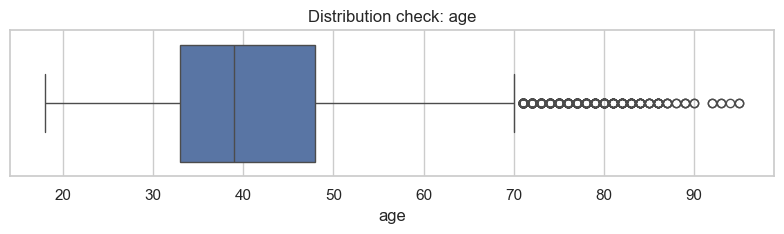

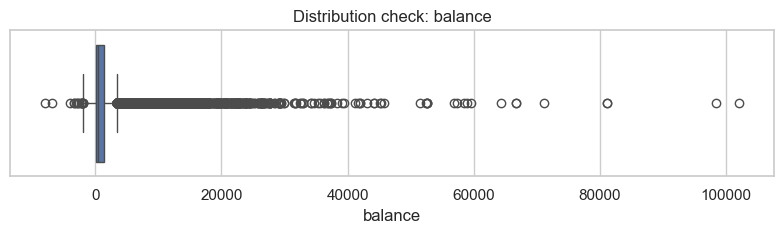

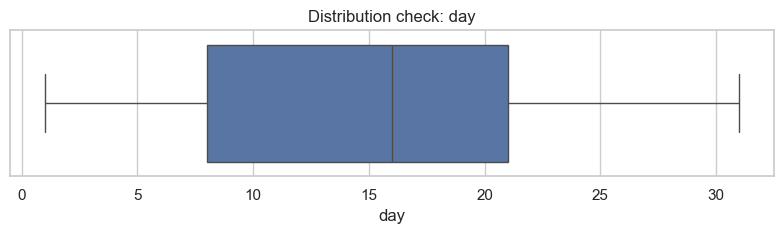

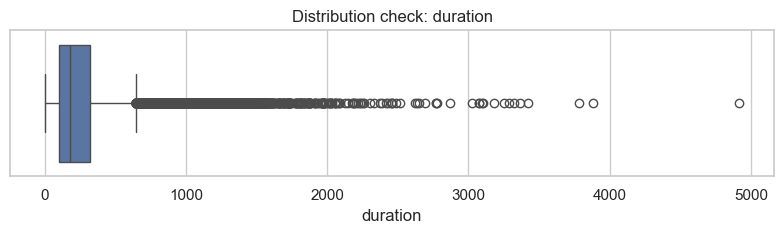

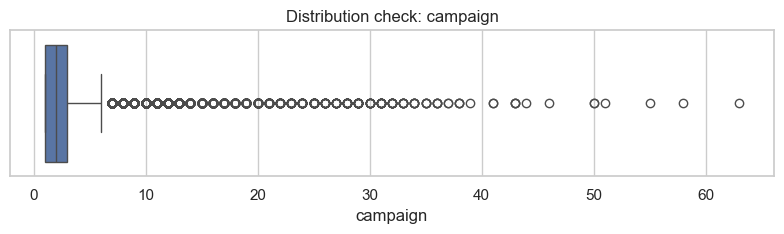

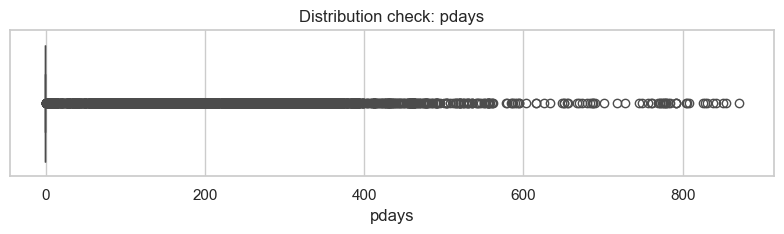

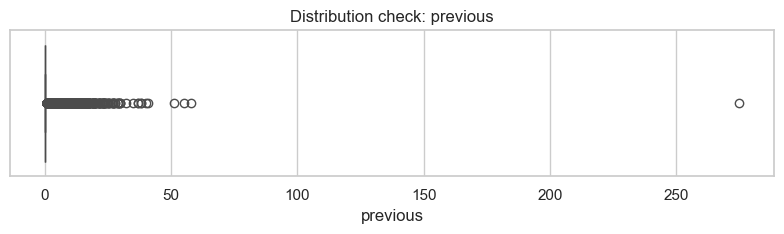

In [8]:
numeric_for_plot = df.select_dtypes(include=np.number).columns.tolist()

for column in numeric_for_plot:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=df[column])
    plt.title(f"Distribution check: {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the data before training the models. The graphs below show the target distribution and how subscription outcomes vary across selected customer and campaign features.

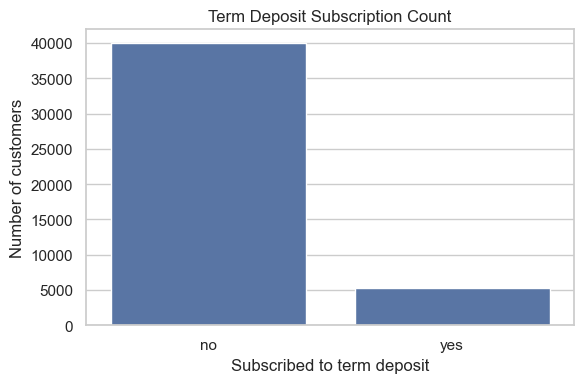

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y", order=["no", "yes"])
plt.title("Term Deposit Subscription Count")
plt.xlabel("Subscribed to term deposit")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

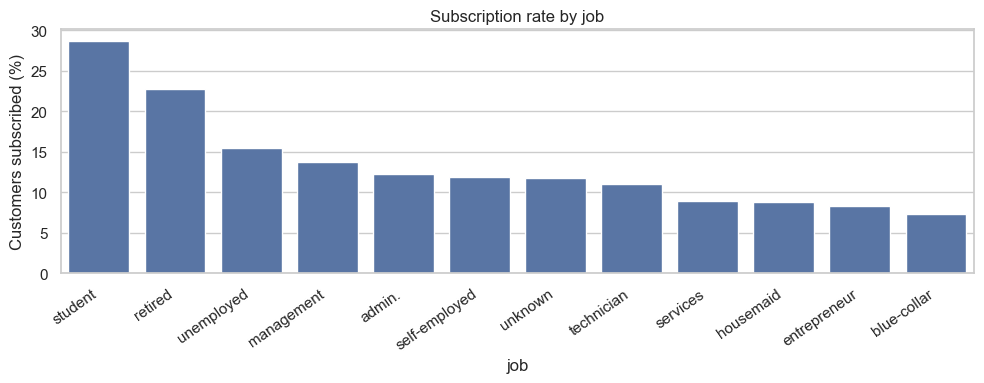

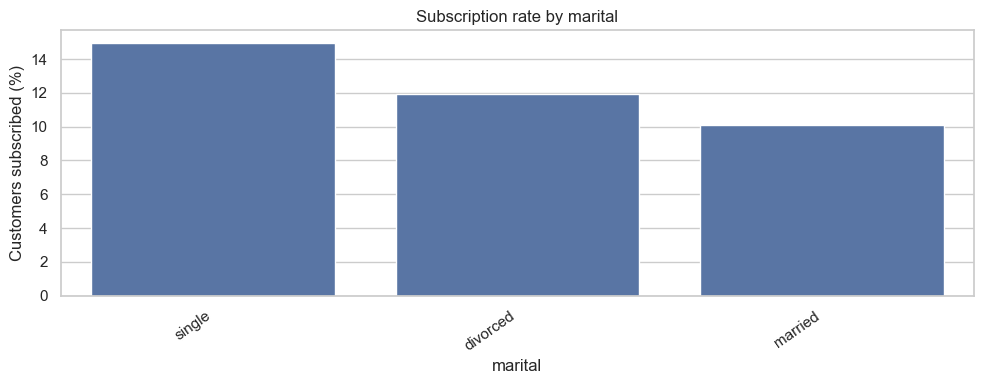

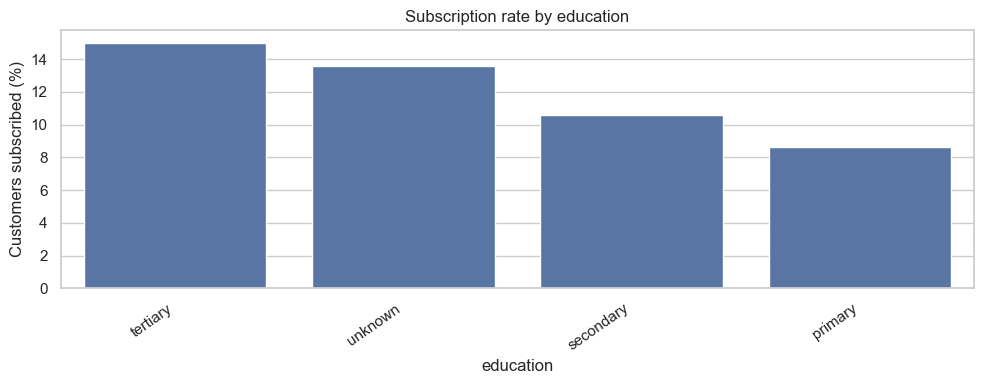

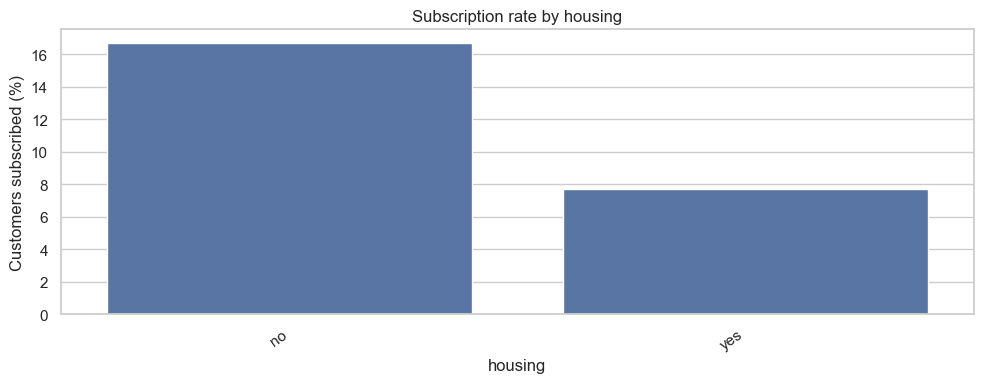

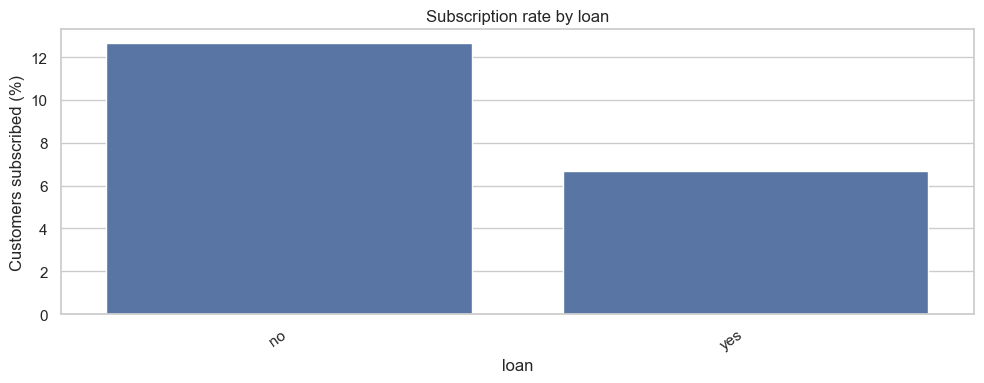

In [10]:
# Subscription percentage for selected categorical features
categorical_eda = ["job", "marital", "education", "housing", "loan"]

for column in categorical_eda:
    rate = (
        df.groupby(column, observed=False)["y"]
        .apply(lambda values: (values == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 4))
    sns.barplot(x=rate.index, y=rate.values)
    plt.title(f"Subscription rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Customers subscribed (%)")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

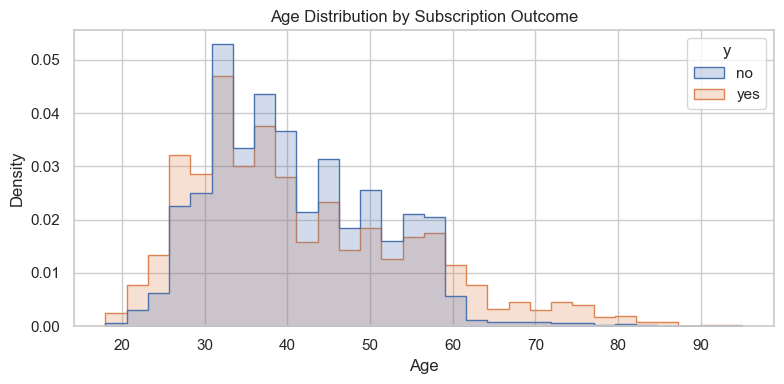

In [11]:
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df,
    x="age",
    hue="y",
    bins=30,
    stat="density",
    common_norm=False,
    element="step"
)
plt.title("Age Distribution by Subscription Outcome")
plt.xlabel("Age")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

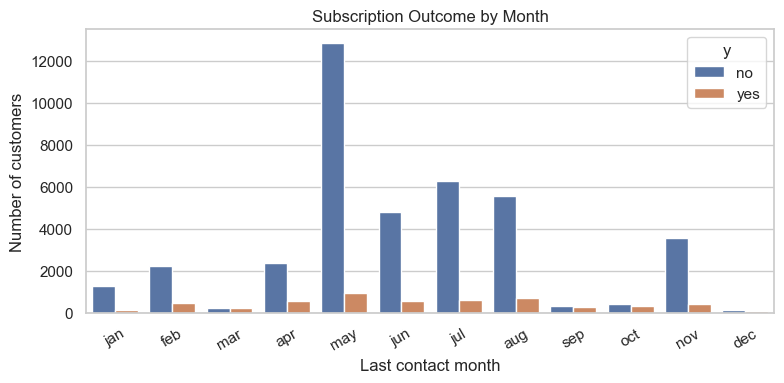

In [12]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="month", hue="y",
              order=["jan", "feb", "mar", "apr", "may", "jun",
                     "jul", "aug", "sep", "oct", "nov", "dec"])
plt.title("Subscription Outcome by Month")
plt.xlabel("Last contact month")
plt.ylabel("Number of customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 8.1 EDA Observations

The exploratory graphs show the following patterns in the dataset:

1. **Target distribution:** The dataset is imbalanced. Out of 45,211 records, 39,922 customers (88.3%) did not subscribe, while 5,289 customers (11.7%) subscribed. This is why accuracy alone is not sufficient for evaluating the models.

2. **Job category:** The subscription-rate graph shows comparatively higher rates among students and retired customers. Blue-collar and entrepreneur categories have lower rates in this dataset.

3. **Marital status and education:** Single customers show a higher subscription rate than married customers in the graph. Customers with tertiary education also show a higher rate than those with primary education.

4. **Housing and personal loans:** Customers without a housing loan or personal loan show higher subscription rates than customers who have these loans.

5. **Age distribution:** Most records are concentrated around the adult age groups, especially the thirties and forties. The graph also shows subscription records among older customers. Age alone does not determine whether a customer subscribes.

6. **Last contact month:** May has the largest number of campaign records in the month-wise count plot. This graph shows the number of contacts in each month, not the subscription rate, so it should not be interpreted as proving that May has the highest likelihood of subscription.

These observations describe patterns in this dataset. They do not establish that any one customer characteristic directly causes a person to subscribe.

## 9. Data Preprocessing

Machine learning algorithms require the input data to be in a suitable numerical format.

The following preparation steps are used:

1. **Separate features and target:** `y` is the target column and the remaining selected columns are inputs.
2. **Exclude `duration`:** the call duration is not available before the call and would cause information leakage for the intended prediction.
3. **Categorical encoding:** One-Hot Encoding converts text categories into numerical columns.
4. **Numerical scaling:** StandardScaler standardises numerical features for Logistic Regression.
5. **Missing-value handling:** numerical missing values are filled with the median and categorical missing values with the most frequent category.

The preprocessing steps are placed inside a Scikit-learn pipeline. This means the imputer, encoder and scaler are fitted using training data only, which helps prevent information from the test set leaking into training.

In [13]:
# Separate input features and target label
X = df.drop(columns=["y", "duration"])
y = df["y"].map({"no": 0, "yes": 1})

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)
print("\nTarget classes (0 = no, 1 = yes):")
print(y.value_counts())

Numerical features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Target classes (0 = no, 1 = yes):
y
0    39922
1     5289
Name: count, dtype: int64


### 9.1 Training, Validation and Testing Split

The dataset is divided into three parts:

- **64% Training data:** Used to train the classification models.
- **16% Validation data:** Used to compare models and select the best-performing model.
- **20% Testing data:** Kept untouched during model selection and used only for final evaluation.

Stratified sampling (`stratify=y`) maintains approximately the same proportion of subscribers and non-subscribers in all three datasets. A fixed random state makes the split reproducible.

In [14]:
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split training data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train_full
)

print("Training records:", X_train.shape[0])
print("Validation records:", X_val.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
display(y_val.value_counts(normalize=True))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True))


Training records: 28934
Validation records: 7234
Testing records: 9043

Training target distribution:


y
0    0.88301
1    0.11699
Name: proportion, dtype: float64


Validation target distribution:


y
0    0.883052
1    0.116948
Name: proportion, dtype: float64


Testing target distribution:


y
0    0.883003
1    0.116997
Name: proportion, dtype: float64

### 9.2 Preprocessing pipeline

The numerical and categorical columns need different preprocessing. A `ColumnTransformer` applies the correct steps to each type of column.

- Numerical columns: median imputation followed by standardisation.
- Categorical columns: most-frequent imputation followed by one-hot encoding.

In [15]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

## 10. Model Selection and Implementation

Three classification algorithms are used in this project.

### 10.1 Logistic Regression

Logistic Regression is a classification algorithm that estimates the probability of a record belonging to a class. It is used as a baseline model because it is relatively simple and its results can be interpreted through the relationship between input features and the predicted probability.

### 10.2 Decision Tree Classifier

A Decision Tree makes predictions by splitting the data into smaller groups using feature-based conditions. It is easy to explain because its decisions can be represented as a tree of rules. However, a tree that grows too deep may overfit the training data.

### 10.3 Random Forest Classifier

Random Forest combines predictions from multiple decision trees. Each tree is trained using a different sample of the training data and considers a subset of features. Combining the trees can make the model more stable than relying on a single decision tree.

### Why these three models?

These models provide three useful levels of comparison: a linear baseline, a single tree-based model and an ensemble of trees. This makes it possible to compare their predictive performance and explainability on the same dataset.

The target classes are imbalanced. The models therefore use `class_weight="balanced"` where supported, so that the smaller positive class receives greater weight during model fitting.

In [16]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[
     ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])
    for name, model in models.items()
}

print("Models prepared:", ", ".join(pipelines.keys()))

Models prepared: Logistic Regression, Decision Tree, Random Forest


## 11. Model Training

Each pipeline first preprocesses the input columns and then trains the selected classifier. All three models are trained using the same training dataset to ensure a fair comparison. Their performance is compared using the validation dataset.

In [17]:
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


## 12. Model Evaluation

The three classification models are evaluated on the validation dataset to compare their performance and select the best model.

The following evaluation measures are used:

- **Accuracy:** Proportion of all predictions that are correct.
- **Precision:** Among customers predicted as subscribers, how many actually subscribed.
- **Recall:** Among actual subscribers, how many the model identified.
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Measures how well the model separates the two classes across different classification thresholds.
- **Confusion matrix:** Shows true negatives, false positives, false negatives and true positives.

Since the target classes are imbalanced, accuracy alone is not sufficient. Precision, recall and F1-score for the positive class (`yes`) are also important.

In [18]:


results = []
predictions = {}
probabilities = {}

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision (yes)": precision_score(y_val, y_pred, zero_division=0),
        "Recall (yes)": recall_score(y_val, y_pred, zero_division=0),
        "F1-score (yes)": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,Accuracy,Precision (yes),Recall (yes),F1-score (yes),ROC-AUC
Model,,,,,
Logistic Regression,0.7563,0.2686,0.6288,0.3764,0.7681
Decision Tree,0.8307,0.3574,0.5615,0.4368,0.7528
Random Forest,0.8343,0.3711,0.6005,0.4587,0.8008


### 12.1 Classification reports

The classification report provides precision, recall and F1-score for both target classes, along with macro and weighted averages.

In [19]:
for name, y_pred in predictions.items():
    print("=" * 70)
    print(name)
    print(classification_report(
        y_val,
        y_pred,
        labels=[0, 1],
        target_names=["No subscription", "Subscription"],
        zero_division=0
    ))

Logistic Regression
                 precision    recall  f1-score   support

No subscription       0.94      0.77      0.85      6388
   Subscription       0.27      0.63      0.38       846

       accuracy                           0.76      7234
      macro avg       0.60      0.70      0.61      7234
   weighted avg       0.86      0.76      0.79      7234

Decision Tree
                 precision    recall  f1-score   support

No subscription       0.94      0.87      0.90      6388
   Subscription       0.36      0.56      0.44       846

       accuracy                           0.83      7234
      macro avg       0.65      0.71      0.67      7234
   weighted avg       0.87      0.83      0.85      7234

Random Forest
                 precision    recall  f1-score   support

No subscription       0.94      0.87      0.90      6388
   Subscription       0.37      0.60      0.46       846

       accuracy                           0.83      7234
      macro avg       0.66      

### 12.2 Confusion matrices

A confusion matrix gives a more detailed view of the types of prediction made by each model. In this project, a false negative means that a customer who subscribed was predicted as not subscribing. A false positive means that a customer who did not subscribe was predicted as subscribing.

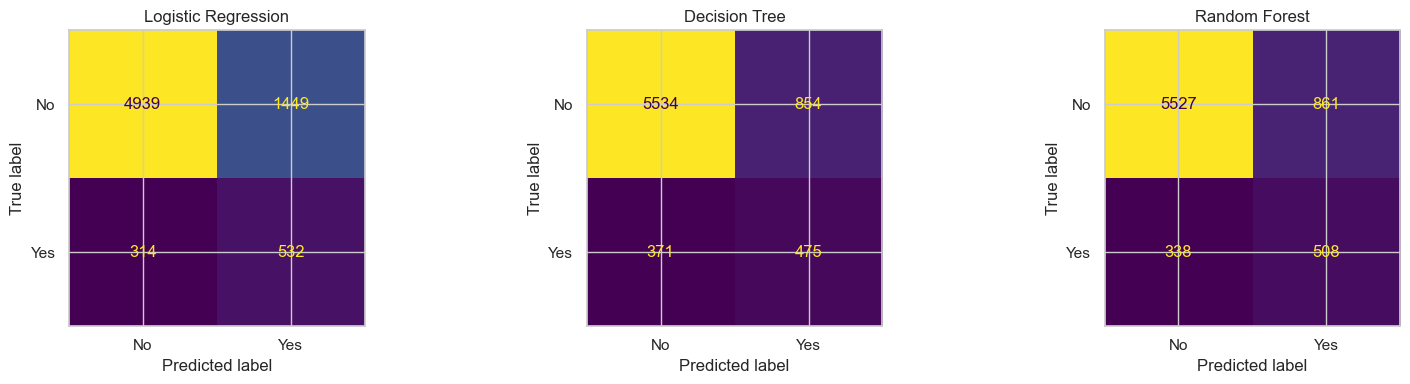

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    )

    display_obj.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)

plt.tight_layout()
plt.show()

### 12.3 ROC curves

The ROC curve shows the relationship between the true positive rate and false positive rate at different classification thresholds. A curve closer to the top-left corner generally indicates better separation of the classes.

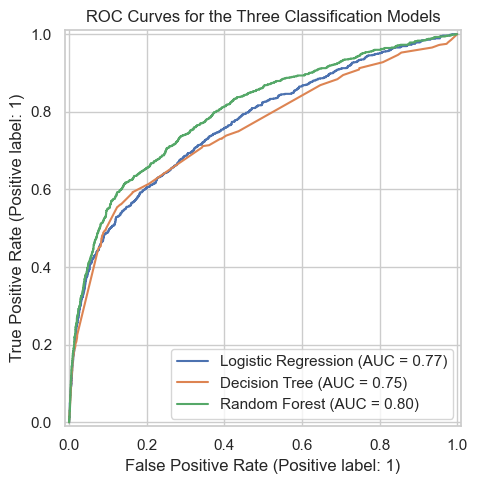

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, y_prob in probabilities.items():
    RocCurveDisplay.from_predictions(
        y_val,
        y_prob,
        name=name,
        ax=ax
    )

ax.set_title("ROC Curves for the Three Classification Models")
plt.tight_layout()
plt.show()

## 13. Model Comparison and Final Model Selection

The three classification models are compared using their validation-set results. The F1-score for the positive class (`yes`) is used as the primary selection measure because it balances precision and recall.

ROC-AUC is also considered to understand how well each model distinguishes between subscribers and non-subscribers.

The model with the highest positive-class F1-score on the validation dataset is selected for final evaluation. The test dataset remains untouched during model selection.

In [22]:
comparison = results_df.sort_values(
    by=["F1-score (yes)", "ROC-AUC"],
    ascending=False
)

display(comparison.round(4))

best_model_name = comparison.index[0]

print("Selected model based on validation F1-score:", best_model_name)

,Accuracy,Precision (yes),Recall (yes),F1-score (yes),ROC-AUC
Model,,,,,
Random Forest,0.8343,0.3711,0.6005,0.4587,0.8008
Decision Tree,0.8307,0.3574,0.5615,0.4368,0.7528
Logistic Regression,0.7563,0.2686,0.6288,0.3764,0.7681


Selected model based on validation F1-score: Random Forest


### 13.1 Interpretation of the Comparison

The three classification models were compared using validation-set performance. Random Forest achieved the highest F1-score for the positive class and was therefore selected as the best-performing model.

The F1-score is important in this project because the dataset contains significantly more non-subscribers than subscribers. Accuracy alone may not properly represent how well a model identifies customers who actually subscribe.

After selecting Random Forest using validation results, the model was retrained on the combined training and validation datasets. Its final performance was then measured using the previously untouched test dataset.

This approach helps maintain a fair evaluation and avoids using test data during model selection.

## 14. Demonstration: Predicting for a Customer Record

To demonstrate how the selected model can be used, one record from the test set is passed to the model. The output includes the predicted class and the estimated probability of subscription.

This is an example prediction from an existing held-out record. It is not a guarantee of the customer's actual decision.

Best Model: Random Forest

FINAL TEST RESULTS
                 precision    recall  f1-score   support

No subscription       0.94      0.86      0.90      7985
   Subscription       0.36      0.60      0.45      1058

       accuracy                           0.83      9043
      macro avg       0.65      0.73      0.67      9043
   weighted avg       0.87      0.83      0.85      9043

Accuracy: 0.8285967046334182
Precision: 0.3597491448118586
Recall: 0.5964083175803403
F1-score: 0.4487908961593172
ROC-AUC: 0.7989949255042239


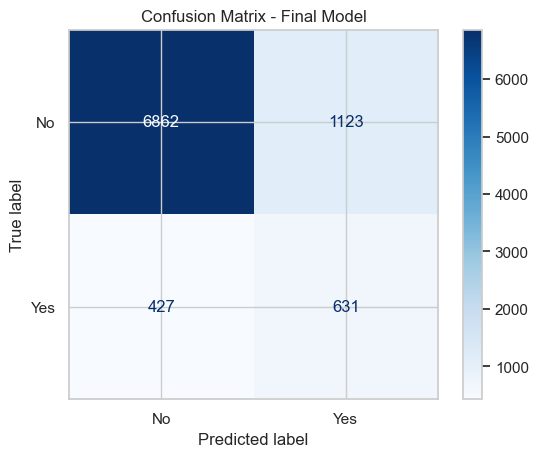

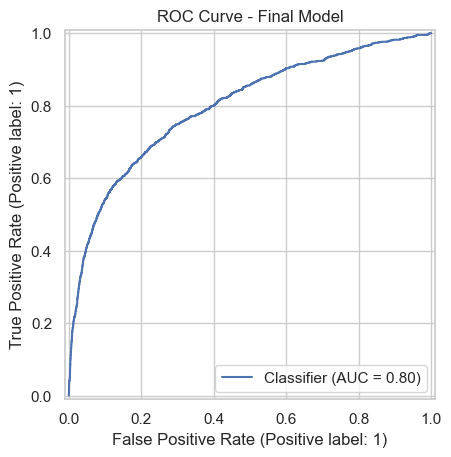

In [23]:

from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

# Select the best model using validation F1-score
best_model_name = results_df["F1-score (yes)"].idxmax()

print("Best Model:", best_model_name)

# Combine training and validation data
X_train_final = pd.concat([X_train, X_val])
y_train_final = pd.concat([y_train, y_val])

# Create and train the final model
final_model = clone(pipelines[best_model_name])
final_model.fit(X_train_final, y_train_final)

# Evaluate on untouched test data
y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

print("\nFINAL TEST RESULTS")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No subscription", "Subscription"],
    zero_division=0
))

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_test_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=["No", "Yes"],
    cmap="Blues"
)
plt.title("Confusion Matrix - Final Model")
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(y_test, y_test_prob)
plt.title("ROC Curve - Final Model")
plt.show()


In [24]:
   sample_customer = X_test.iloc[[0]]
   actual_result = y_test.iloc[0]

   predicted_result = final_model.predict(sample_customer)[0]
   predicted_probability = final_model.predict_proba(sample_customer)[0, 1]

   print("Customer details:")
   display(sample_customer)

   print("Actual outcome:", "Yes" if actual_result == 1 else "No")
   print("Predicted outcome:", "Yes" if predicted_result == 1 else "No")
   print(f"Estimated probability of subscription: {predicted_probability:.2%}")

Customer details:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
1392,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,2,-1,0,unknown


Actual outcome: No
Predicted outcome: No
Estimated probability of subscription: 13.94%


## 15. Results and Discussion

Three classification algorithms—Logistic Regression, Decision Tree, and Random Forest—were trained using the training dataset and evaluated on the validation dataset. The models were compared using accuracy, precision, recall, F1-score, and ROC-AUC.

Based on the validation F1-score for the positive class (customers who subscribed to a term deposit), the Random Forest Classifier was selected as the best-performing model.

The selected Random Forest model was then retrained using the combined training and validation datasets and evaluated on the previously untouched test dataset containing 9,043 records.

### Final Test Results – Random Forest

| Evaluation Metric | Result |
|---|---:|
| Accuracy | 82.86% |
| Precision (yes) | 35.97% |
| Recall (yes) | 59.64% |
| F1-score (yes) | 44.88% |
| ROC-AUC | 79.90% |

### Discussion

The Random Forest model achieved an accuracy of 82.86%, indicating that it correctly classified approximately 83% of the customers in the test dataset.

Its precision of 35.97% means that approximately 36% of the customers predicted as subscribers actually subscribed to a term deposit. The recall of 59.64% indicates that the model successfully identified approximately 60% of all actual subscribers.

The F1-score of 44.88% represents the balance between precision and recall. The ROC-AUC score of 79.90% indicates that the model has a reasonable ability to distinguish between subscribers and non-subscribers.

The dataset is imbalanced, with approximately 88.3% non-subscribers and 11.7% subscribers. Therefore, accuracy alone is not sufficient to evaluate model performance. Precision, recall, and F1-score provide a better understanding of how effectively the model identifies potential subscribers.

The confusion matrix and ROC curve provide additional insights into the model's classification performance.

Overall, the Random Forest Classifier was selected based on its validation performance and achieved reasonable results on unseen test data. However, its relatively low precision indicates that further improvements, such as hyperparameter tuning and threshold optimization, could help reduce false positive predictions.


## 16. Challenges and Solutions

| Challenge | Approach used |
|---|---|
| The target classes are imbalanced | Used `class_weight="balanced"` and evaluated precision, recall and F1-score instead of relying only on accuracy |
| The dataset contains categorical variables | Applied One-Hot Encoding |
| Numerical features have different scales | Applied StandardScaler in the preprocessing pipeline |
| Some columns contain special values such as `pdays = -1` | Retained the documented value to represent no previous contact |
| Call duration is not available before a call | Excluded `duration` to avoid information leakage |
| A model may perform well on training data but poorly on unseen data | Used separate stratified training, validation and test sets; kept the test set untouched for final evaluation |

## 17. Limitations

1. The dataset represents marketing campaigns from a particular Portuguese banking institution and may not reflect current customer behaviour or other banks.
2. The data contains more records of customers who did not subscribe than customers who subscribed.
3. The model uses the available recorded features; other factors that affect a customer's decision may not be included.
4. The prediction is an estimate and cannot guarantee that a customer will subscribe.
5. The results depend on the selected train-test split and model settings.

## 18. Future Scope

1. Test the model on more recent campaign data.
2. Compare additional algorithms and tune model parameters.
3. Study different probability thresholds based on the bank's campaign objectives.
4. Evaluate the model on data from other campaigns or institutions.
5. Monitor model performance over time to identify changes in customer behaviour.

## 19. Conclusion

This project developed a machine learning classification workflow to predict whether a customer would subscribe to a bank term deposit. The UCI Bank Marketing dataset was explored, cleaned and prepared before training Logistic Regression, Decision Tree and Random Forest classifiers.

The models were compared using validation data, and Random Forest was selected based on its positive-class F1-score. The selected model was retrained using the combined training and validation datasets and evaluated on the untouched test dataset.

Random Forest achieved an accuracy of 82.86%, precision of 35.97%, recall of 59.64%, F1-score of 44.88% and ROC-AUC of 79.90% on the final test data. The results demonstrate how machine learning can help identify potential customers and support more focused marketing campaigns. The model should be tested on newer and more varied data before being used in a real banking environment.

## 20. References

1. Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306
2. UCI Machine Learning Repository. *Bank Marketing Dataset*. https://archive.ics.uci.edu/dataset/222/bank%2Bmarketing
3. Scikit-learn documentation. https://scikit-learn.org/stable/
4. Pandas documentation. https://pandas.pydata.org/docs/
5. NumPy documentation. https://numpy.org/doc/
6. Matplotlib documentation. https://matplotlib.org/stable/
7. Seaborn documentation. https://seaborn.pydata.org/